# GPR26 + glutamate: where the colocalisation is

The pair that survived furthest in the orphan screen. SLC17A7 is VGLUT1, the vesicular
glutamate transporter that marks glutamatergic neurons, so it stands in for glutamate
itself in the spatial data.

This asks one question: is the co-occurrence specific, or does it follow what the atlas
happens to contain? The atlas is not evenly sampled, and the single largest tissue in it is
pancreas at 8.8% of all calls, so raw counts cannot answer that.


In [1]:
import pyarrow.parquet as pq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, '/data/yzy21/yy/space_agent/manuscript')
import figstyle
from figstyle import RED, BLUE, GREY, GREY_L, INK, MUT
figstyle.use_house_style('print')
LR = '/data/yzy21/yy/space_agent/lr_atlas'

## The pair's own calls

`orphan_pair_calls.parquet` holds 112,426,869 sample-by-group calls. Pair code 54244 is
GPR26-SLC17A7.

In [2]:
import pyarrow as pa, pyarrow.compute as pc
f = pq.ParquetFile(f'{LR}/bench/orphan_pair_calls.parquet')
keep = []
for i in range(f.metadata.num_row_groups):
    t = f.read_row_group(i)
    sub = t.filter(pc.is_in(t['pair_code'], value_set=pa.array([54244])))
    if sub.num_rows:
        keep.append(sub.to_pandas())
calls = pd.concat(keep)
print(f"{len(calls):,} calls, {calls['sample'].nunique():,} samples, "
      f"{calls.tissue.nunique()} tissues, {calls.group_id.nunique():,} groups")

1,345 calls, 1,345 samples, 90 tissues, 530 groups


## The background every count has to be read against

The denominator is every call in the atlas, not a sample of it. A first pass used 12 of the
108 row groups and reported dorsolateral prefrontal cortex at 12.9-fold; over the full
file it is 5.0. The fine cortical labels were simply under-represented in the sample, and
three of them looked infinitely enriched because the sampled background held none of them
at all.

In [3]:
tot = {}
for i in range(f.metadata.num_row_groups):
    vc = f.read_row_group(i, columns=['tissue']).column('tissue').to_pandas().value_counts()
    for k, v in vc.items():
        tot[k] = tot.get(k, 0) + int(v)
bg = pd.Series(tot).sort_values(ascending=False)
print(f"background: {bg.sum():,} calls over {len(bg)} tissues")
print(f"largest tissue in the atlas: {bg.index[0]} at {100*bg.iloc[0]/bg.sum():.1f}%")

background: 112,426,869 calls over 234 tissues
largest tissue in the atlas: brain at 10.5%


In [4]:
hit = calls.tissue.value_counts()
d = pd.DataFrame({'calls': hit})
d['atlas_calls'] = [int(bg.get(t, 0)) for t in d.index]
d['pair_frac'] = d.calls / d.calls.sum()
d['atlas_frac'] = d.atlas_calls / bg.sum()
d['fold'] = d.pair_frac / d.atlas_frac.replace(0, np.nan)
d = d[d.calls >= 20].sort_values('fold', ascending=False)
d

,calls,atlas_calls,pair_frac,atlas_frac,fold
tissue,,,,,
brodmann_1909_area_44,129,1872934,0.095911,0.016659,5.757250
brodmann_1909_area_46,100,1500457,0.074349,0.013346,5.570886
medial_motor_cortex,33,529423,0.024535,0.004709,5.210255
dorsolateral_prefrontal_cortex,70,1168849,0.052045,0.010397,5.005961
lateral_motor_cortex,48,872940,0.035688,0.007765,4.596261
primary_motor_cortex_ba4,44,918686,0.032714,0.008171,4.003441
primary_motor_cortex,25,534293,0.018587,0.004752,3.911185
dorsal_anterior_cingulate_cortex,21,466146,0.015613,0.004146,3.765695
entorhinal_cortex,33,746775,0.024535,0.006642,3.693788


## The figure

**a** enrichment over the atlas background, for every tissue with at least 20 calls.
**b** the same tissues as raw share, to show what the background correction does.

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


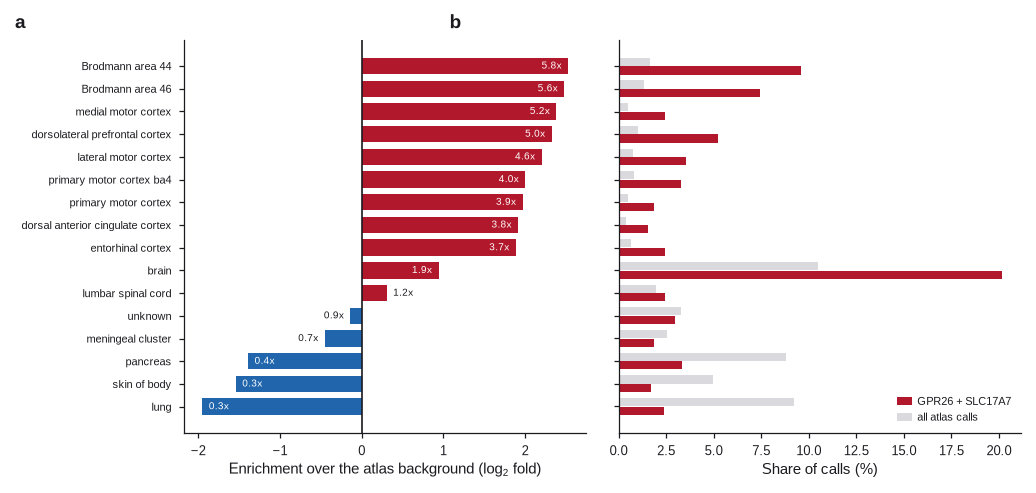

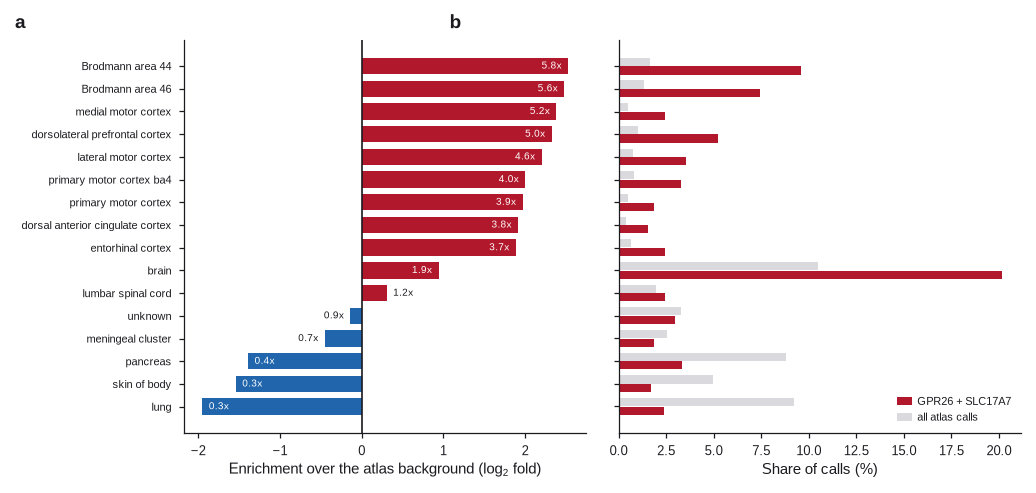

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(figstyle.FULL_WIDTH, 3.4),
                         gridspec_kw={'width_ratios': [1, 1], 'wspace': 0.08})

lab = [t.replace('_', ' ').replace('brodmann 1909 ', 'Brodmann ') for t in d.index]
y = np.arange(len(d))[::-1]
col = [RED if f > 1 else BLUE for f in d.fold]

ax = axes[0]
ax.barh(y, np.log2(d.fold), color=col, height=0.72)
ax.axvline(0, color=INK, lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(lab, fontsize=5.4)
ax.set_xlabel('Enrichment over the atlas background (log$_2$ fold)')
for yy, f_, n in zip(y, d.fold, d.calls):
    # inside the bar when it is long enough, anchored at the end nearest zero
    # so a label can never run off the axis at either side
    w = np.log2(f_)
    if abs(w) > 0.9:
        ax.text(w - 0.08 if w > 0 else w + 0.08, yy, f'{f_:.1f}x', va='center',
                ha='right' if w > 0 else 'left', fontsize=4.8, color='white')
    else:
        ax.text(w + 0.08 if w > 0 else w - 0.08, yy, f'{f_:.1f}x', va='center',
                ha='left' if w > 0 else 'right', fontsize=4.8, color=MUT)
figstyle.assert_in_view(ax, np.log2(d.fold.values))

ax = axes[1]
ax.barh(y - 0.19, 100 * d.pair_frac, height=0.36, color=RED, label='GPR26 + SLC17A7')
ax.barh(y + 0.19, 100 * d.atlas_frac, height=0.36, color=GREY_L, label='all atlas calls')
ax.set_yticks(y); ax.set_yticklabels([])      # panel a already names them
ax.set_xlabel('Share of calls (%)')
ax.legend(fontsize=5.2, frameon=False, loc='lower right')
figstyle.assert_in_view(ax, np.concatenate([100*d.pair_frac.values, 100*d.atlas_frac.values]))

for k, ax in zip('ab', axes):
    ax.text(-0.42, 1.02, k, transform=ax.transAxes, fontsize=9, fontweight='bold', va='bottom')
fig.savefig('/data/yzy21/yy/space_agent/manuscript/coloc/gpr26_glutamate_coloc.png',
            dpi=300, bbox_inches='tight')
fig

## What it shows, and what it does not

Cortical areas run 3.7 to 5.8-fold over background: Brodmann 44 and 46, the motor
cortices, dorsolateral prefrontal cortex, entorhinal cortex. Undifferentiated "brain" is
1.9-fold. Pancreas is **depleted at 0.38-fold** despite being the atlas's largest tissue,
and that depletion is what makes this a pattern rather than a reflection of what was
sequenced.

Two caveats that belong on the figure, not in a footnote.

GPR26 is detected in **1.5% of cells** (`det_rate_a` 0.0151). A receptor that sparse makes
any co-occurrence statistic unstable, and this project has already been burnt by reading a
sparse field as a measured absence.

The pair's own spatial significance against the null is **p = 0.49** (`p_full`). It entered
the folded 5,000 on the two-way-null rank, not on raw co-occurrence. So the anatomical
pattern below is specific and the per-pair significance is not, and both statements are
true at once.